# ABM demo

Run all cells in the **abm** environment. Edit `params` for the simulation or `animation_params` for its appearance.

Uses the settings from `paper/section_1/demo_new.ipynb`: 10 killers, 40 targets, 15 minutes, confined boundaries. `KTSimulator` calls the shared engine in `src`; `RECOVERY=False` selects instant killing.

The final cell regenerates `vis_test.gif` at the repository root.

In [1]:
from pathlib import Path
from time import perf_counter
import sys

import scienceplots
import matplotlib.pyplot as plt
from IPython.display import Image, display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "script/simulator/simulator.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the MantiShrimp checkout.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from script.simulator.simulator import KTSimulator
from script.simulator.virsualisation import animate_KT

plt.style.use("science")
plt.rcParams.update({
    "legend.fontsize": 20, "xtick.labelsize": 20, "ytick.labelsize": 20,
    "axes.titlesize": 22, "axes.labelsize": 22,
})

In [2]:
SEED = 42
params = {
    # Population and domain
    "N_KILLER": 10, "N_TARGET": 40,
    "KILLER_RADIUS": 12.5, "TARGET_RADIUS": 15.0,
    "SIM_DURATION": 15.0, "DT0": 1 / 25, "DS": 1.0,
    "RNG_SEED": SEED, "ini_seed": SEED,
    "BOX_X_MIN": -600.0, "BOX_X_MAX": 600.0,
    "BOX_Y_MIN": -600.0, "BOX_Y_MAX": 600.0,
    "boundary_condition": "confined",
    "region_shape": "square", "init_mode": "uniform", "init_sigma": None,
    "init_cell_bound": None, "ini_cell_centre": (0.0, 0.0),
    "ini_cell_region_radius": 300.0, "min_distance_factor": 4,

    # Motion and mechanics
    "KILLER_POL_DECAY": 2.5, "TARGET_POL_DECAY": 5,
    "KILLER_POL_NOISE": 2.0, "TARGET_POL_NOISE": 0.75,
    "KILLER_MOTILITY": 175.0, "TARGET_MOTILITY": 125.0,
    "KILLER_TRANS_NOISE": 0.75, "TARGET_TRANS_NOISE": 0.2,
    "KREP_KK": 250.0, "KREP_TT": 250.0, "KREP_KT": 250.0,
    "F_A_KT": 25.0, "K_BIND": 3.0, "K_UNBIND": 0.5,

    # Killing and exhaustion
    "KILL_PROBABILISTIC": True, "KILL_PROB_INIT": 1.0,
    "kill_prob_mode": "constant", "DECAY_PER_CONTACT": 0.05,
    "KILLER_STATE_INIT": 1.0, "TARGET_STATE_INIT": 1.0,
    "MIN_STATE_DECAY_dt": 0.001, "MAX_STATE_DECAY_dt": 0.1,
    "DEATH_FAC_INIT": None, "KILL_DEATH_THRESHOLD": 1.0,
    "RECOVERY": False, "RECOVERY_SPEED": 0.0,

    # Inactive compatibility arguments retained from demo_new.
    "F_A_KK": 1.0, "F_A_TT": 1.0, "DISAPPEAR_DELAY": 0.5,
}

PLOT_MARGIN = 0.06
animation_params = {
    "dead_target_radius": params["TARGET_RADIUS"],
    "killer_colour": "#4477AA", "live_target_colour": "#228833", "dead_target_colour": "#EE6677",
    "traj_steps": 100, "traj_linewidth": 2, "traj_alpha": 0.45, "cir_linewidth": 1.5,
    "figsize": (6, 7), "fig_dpi": 100,
    "interval": 40, "frame_step": 10, "gif_fps": 25,
    "add_swatch_legend": True, "legend_labels": None,
}

In [3]:
started = perf_counter()
(cell_history_df, killer_positions, target_positions,
 killingProbability_history, DeathFactor_history, sim_settings) = KTSimulator(**params)

last_step = cell_history_df["step"].max()
final_targets = cell_history_df.loc[
    cell_history_df["step"].eq(last_step) & cell_history_df["cell_type"].eq("target")
]
print(f"Finished in {perf_counter() - started:.1f} s; {last_step + 1:,} recorded steps.")
print(f"Targets alive: {int(final_targets['alive_status'].sum())}/{params['N_TARGET']}")
cell_history_df.head()

Finished in 4.9 s; 5,424 recorded steps.
Targets alive: 26/40


,step,time,cell_type,cell_id,x,y,mu_x,mu_y,alive_status,cell_state,Death_Factor,contacts,killing_P,killed_by
0,0,0.0,killer,0,532.905574,-323.746158,0.0,0.0,True,1.0,NaN,[],1.0,None
1,0,0.0,killer,1,-444.811503,-496.033232,0.0,0.0,True,1.0,NaN,[],1.0,None
2,0,0.0,killer,2,-458.479226,466.741552,0.0,0.0,True,1.0,NaN,[],1.0,None
3,0,0.0,killer,3,450.790164,93.740319,0.0,0.0,True,1.0,NaN,[],1.0,None
4,0,0.0,killer,4,-302.020049,-365.839966,0.0,0.0,True,1.0,NaN,[],1.0,None


## Animation

The GIF uses the reference colours, trails and frame spacing. Playback intervals are fixed; simulation timesteps are adaptive. Cell circles do not indicate whether a bond is present.

Animation saved as GIF: /Users/marsian/PhD_LifeSciRes/MantiShrimp/vis_test.gif


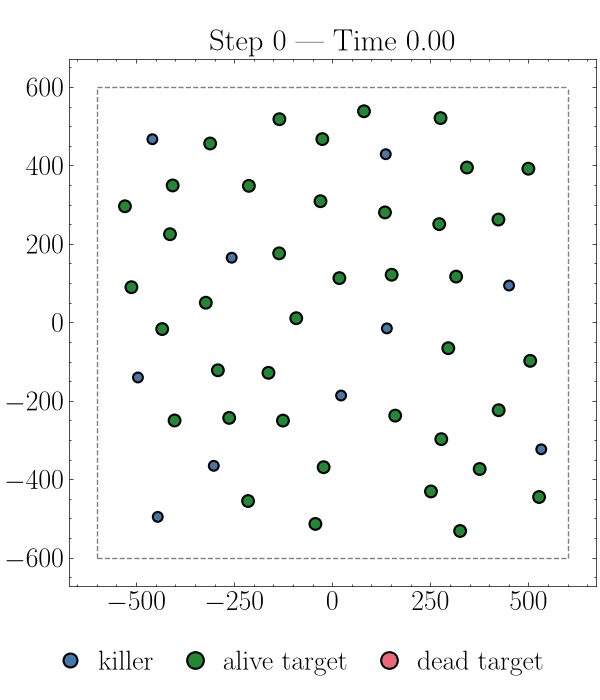

In [4]:
sim_box = tuple(sim_settings[key] for key in
                ("BOX_X_MIN", "BOX_X_MAX", "BOX_Y_MIN", "BOX_Y_MAX"))
xwidth, ywidth = sim_box[1] - sim_box[0], sim_box[3] - sim_box[2]
ax_box = (
    sim_box[0] - PLOT_MARGIN * xwidth, sim_box[1] + PLOT_MARGIN * xwidth,
    sim_box[2] - PLOT_MARGIN * ywidth, sim_box[3] + PLOT_MARGIN * ywidth,
)
gif_path = PROJECT_ROOT / "vis_test.gif"
animation = animate_KT(
    cell_history_df, killer_positions, target_positions,
    killer_radius=sim_settings["KILLER_RADIUS"], target_radius=sim_settings["TARGET_RADIUS"],
    box=sim_box, ax_box=ax_box, boundary_condition=sim_settings["boundary_condition"],
    save_gif_path=str(gif_path), render_html=False, **animation_params,
)
display(Image(filename=str(gif_path)))